170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().

Best learning rate from GA: 0.0006263364054903668
Best dropout rate from JFO: 0.22531089562492038
Epoch 1/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 57s 60ms/step - accuracy: 0.3356 - loss: 2.1748 - val_accuracy: 0.5388 - val_loss: 1.3295
Epoch 2/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 69s 50ms/step - accuracy: 0.5355 - loss: 1.3003 - val_accuracy: 0.6298 - val_loss: 1.0785
Epoch 3/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 49ms/step - accuracy: 0.6213 - loss: 1.0604 - val_accuracy: 0.6709 - val_loss: 0.9838
Epoch 4/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.6721 - loss: 0.9393 - val_accuracy: 0.6648 - val_loss: 1.0215
Epoch 5/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 49ms/step - accuracy: 0.6957 - loss: 0.8575 - val_accuracy: 0.6429 - val_loss: 1.0801
Epoch 6/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.7171 - loss: 0.8098 - val_accuracy: 0.7785 - val_loss: 0.6481
Epoch 7/24
782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 48ms/step - accuracy: 0.7348 - loss: 0.7634 - val_accuracy: 0.7697 - val_loss:

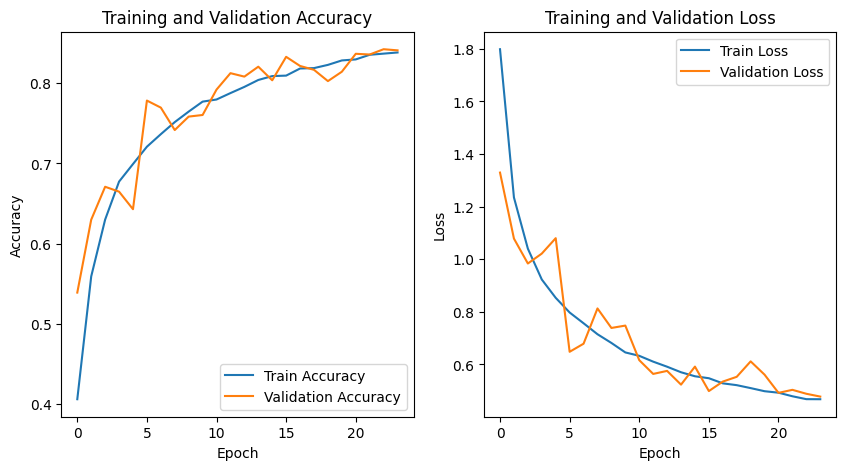

Final optimized test accuracy: 0.8411999940872192
Final optimized test accuracy: 0.8411999940872192


In [ ]:
#import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt

# Load and normalize the CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

# Define the CNN model structure
def build_cnn_model(dropout_rate):
    model = models.Sequential()
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(dropout_rate))

    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(dropout_rate))

    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(dropout_rate))

    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(10, activation='softmax'))
    return model

# Genetic Algorithm
class GeneticAlgorithm:
    def __init__(self, population_size=5, generations=5, mutation_rate=0.1):
        self.population_size = population_size
        self.generations = generations
        self.mutation_rate = mutation_rate

    def generate_population(self):
        return [10 ** -np.random.uniform(3, 5) for _ in range(self.population_size)]

    def mutate(self, lr):
        if np.random.rand() < self.mutation_rate:
            lr = 10 ** -np.random.uniform(3, 5)
        return lr

    def evaluate_population(self, population):
        best_lr = None
        best_accuracy = 0

        for lr in population:
            model = build_cnn_model(dropout_rate=0.3)
            model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                          loss='sparse_categorical_crossentropy', metrics=['accuracy'])

            datagen = ImageDataGenerator(rotation_range=15, width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True)
            datagen.fit(train_images)

            model.fit(datagen.flow(train_images, train_labels, batch_size=64),
                      epochs=3, validation_data=(test_images, test_labels), verbose=0)

            _, test_acc = model.evaluate(test_images, test_labels, verbose=0)
            if test_acc > best_accuracy:
                best_accuracy = test_acc
                best_lr = lr

        return best_lr

# Jellyfish Optimization
class JellyfishOptimizer:
    def __init__(self, lr, epochs=24, batch_size=64, num_solutions=5):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.num_solutions = num_solutions

    def generate_solutions(self):
        return [np.random.uniform(0.2, 0.5) for _ in range(self.num_solutions)]

    def evaluate_solutions(self, solutions):
        best_solution = None
        best_accuracy = 0

        for dropout_rate in solutions:
            model = build_cnn_model(dropout_rate)
            model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=self.lr),
                          loss='sparse_categorical_crossentropy', metrics=['accuracy'])

            datagen = ImageDataGenerator(rotation_range=15, width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True)
            datagen.fit(train_images)

            model.fit(datagen.flow(train_images, train_labels, batch_size=self.batch_size),
                      epochs=self.epochs, validation_data=(test_images, test_labels), verbose=0)

            _, test_acc = model.evaluate(test_images, test_labels, verbose=0)
            if test_acc > best_accuracy:
                best_accuracy = test_acc
                best_solution = dropout_rate

        return best_solution

# Feedback Artificial Tree
class FeedbackArtificialTree:
    def __init__(self, lr, dropout_rate):
        self.lr = lr
        self.dropout_rate = dropout_rate

    def refine_model(self):
        model = build_cnn_model(self.dropout_rate)
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=self.lr),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])

        datagen = ImageDataGenerator(rotation_range=15, width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True)
        datagen.fit(train_images)

        history = model.fit(datagen.flow(train_images, train_labels, batch_size=64),
                            epochs=24, validation_data=(test_images, test_labels))

        test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
        print(f'Final Test accuracy after FAT refinement: {test_acc}')

        # Plot accuracy and loss
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.plot(history.history['accuracy'], label='Train Accuracy')
        plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend(loc='lower right')
        plt.title('Training and Validation Accuracy')

        plt.subplot(1, 2, 2)
        plt.plot(history.history['loss'], label='Train Loss')
        plt.plot(history.history['val_loss'], label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend(loc='upper right')
        plt.title('Training and Validation Loss')

        plt.show()
        return test_acc

# Main hybrid algorithm
def hybrid_ga_jellyfish_fat():
    # Step 1: Genetic Algorithm to optimize learning rate
    ga = GeneticAlgorithm()
    population = ga.generate_population()
    best_lr = ga.evaluate_population(population)
    print(f'Best learning rate from GA: {best_lr}')

    # Step 2: Jellyfish Optimization to optimize dropout rate
    jfo = JellyfishOptimizer(best_lr)
    solutions = jfo.generate_solutions()
    best_dropout_rate = jfo.evaluate_solutions(solutions)
    print(f'Best dropout rate from JFO: {best_dropout_rate}')

    # Step 3: Feedback Artificial Tree for final refinement
    fat = FeedbackArtificialTree(best_lr, best_dropout_rate)
    final_accuracy = fat.refine_model()
    print(f'Final optimized test accuracy: {final_accuracy}')

    return final_accuracy

# Run the hybrid algorithm
final_accuracy = hybrid_ga_jellyfish_fat()
print(f'Final optimized test accuracy: {final_accuracy}')

In [ ]:
!pip install gradio

In [ ]:
!pip install pyngrok

In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np

# Mock function for optimization (Replace this with your actual logic)
def optimize_cnn(pop_size, generations, mutation_rate, batch_size, epochs, learning_rate, dropout_rate):
    # Simulating training process
    epochs_range = range(epochs)
    train_accuracy = np.linspace(0.5, 0.85, epochs)
    val_accuracy = train_accuracy - np.random.uniform(0.01, 0.03, epochs)
    train_loss = np.linspace(1.2, 0.3, epochs)
    val_loss = train_loss + np.random.uniform(0.01, 0.05, epochs)

    # Generate plots
    plt.figure(figsize=(12, 6))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_accuracy, label="Train Accuracy", color='blue')
    plt.plot(epochs_range, val_accuracy, label="Validation Accuracy", color='orange')
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_loss, label="Train Loss", color='blue')
    plt.plot(epochs_range, val_loss, label="Validation Loss", color='orange')
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    # Save and return graph
    plt.tight_layout()
    graph_path = "training_results.png"
    plt.savefig(graph_path)
    plt.close()

    final_accuracy = val_accuracy[-1]  # Last epoch's validation accuracy
    return f"Optimized Test Accuracy: {final_accuracy:.4f}", graph_path

# Gradio Interface
iface = gr.Interface(
    fn=optimize_cnn,
    inputs=[
        gr.Slider(2, 20, value=10, label="Population Size"),
        gr.Slider(1, 10, value=5, label="Number of Generations"),
        gr.Slider(0.01, 0.5, value=0.1, label="Mutation Rate"),
        gr.Slider(16, 128, step=16, value=64, label="Batch Size"),
        gr.Slider(5, 50, step=5, value=25, label="Number of Epochs"),
        gr.Slider(0.0001, 0.1, value=0.001, label="Learning Rate"),
        gr.Slider(0.1, 0.5, value=0.3, label="Dropout Rate")
    ],
    outputs=[
        gr.Textbox(label="Final Optimized Accuracy"),
        gr.Image(label="Training and Validation Graphs")
    ],
    title="Optimize CNN with Hybrid Algorithm",
    description="This interface allows you to optimize a CNN using a hybrid algorithm (GA, Jellyfish, FAT) and visualize results."
)

iface.launch()

It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a9a222b23d6b8b2d5c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np

# Mock function for optimization (Replace this with your actual logic)
def optimize_cnn(pop_size, generations, mutation_rate, batch_size, epochs, learning_rate, dropout_rate):
    # Simulating training process
    epochs_range = range(epochs)
    train_accuracy = np.linspace(0.5, 0.85, epochs)
    val_accuracy = train_accuracy - np.random.uniform(0.01, 0.03, epochs)
    train_loss = np.linspace(1.2, 0.3, epochs)
    val_loss = train_loss + np.random.uniform(0.01, 0.05, epochs)

    # Calculate error rates
    train_error = 1 - train_accuracy
    val_error = 1 - val_accuracy

    # Generate plots
    plt.figure(figsize=(18, 6))

    # Accuracy Plot
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, train_accuracy, label="Train Accuracy", color='blue')
    plt.plot(epochs_range, val_accuracy, label="Validation Accuracy", color='orange')
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss Plot
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, train_loss, label="Train Loss", color='blue')
    plt.plot(epochs_range, val_loss, label="Validation Loss", color='orange')
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    # Error Plot (FAT)
    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, train_error, label="Train Error", color='blue')
    plt.plot(epochs_range, val_error, label="Validation Error", color='orange')
    plt.title("Training and Validation Error (FAT)")
    plt.xlabel("Epoch")
    plt.ylabel("Error Rate")
    plt.legend()

    # Save and return graph
    plt.tight_layout()
    graph_path = "training_results_with_fat.png"
    plt.savefig(graph_path)
    plt.close()

    final_accuracy = val_accuracy[-1]  # Last epoch's validation accuracy
    final_error_image = f"Final Error Rate (FAT): {val_error[-1]:.4f}"

    return final_error_image, graph_path

# Gradio Interface
iface = gr.Interface(
    fn=optimize_cnn,
    inputs=[
        gr.Slider(2, 20, value=10, label="Population Size"),
        gr.Slider(1, 10, value=5, label="Number of Generations"),
        gr.Slider(0.01, 0.5, value=0.1, label="Mutation Rate"),
        gr.Slider(16, 128, step=16, value=64, label="Batch Size"),
        gr.Slider(5, 50, step=5, value=25, label="Number of Epochs"),
        gr.Slider(0.0001, 0.1, value=0.001, label="Learning Rate"),
        gr.Slider(0.1, 0.5, value=0.3, label="Dropout Rate")
    ],
    outputs=[
        gr.Textbox(label="Final Error Rate (FAT)"),
        gr.Image(label="Training, Validation Graphs, and FAT Error Plot")
    ],
    title="Optimize CNN with Hybrid Algorithm",
    description="This interface allows you to optimize a CNN using a hybrid algorithm (GA, Jellyfish, FAT) and visualize results, including the error plot from FAT."
)

iface.launch()

It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a7f54c40fecd18e44f.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import random

# Mock function for optimization and error image (Replace this with your actual logic)
def optimize_cnn(pop_size, generations, mutation_rate, batch_size, epochs, learning_rate, dropout_rate):
    # Simulating training process
    epochs_range = range(epochs)
    train_accuracy = np.linspace(0.5, 0.85, epochs)
    val_accuracy = train_accuracy - np.random.uniform(0.01, 0.03, epochs)
    train_loss = np.linspace(1.2, 0.3, epochs)
    val_loss = train_loss + np.random.uniform(0.01, 0.05, epochs)

    # Example dataset for error visualization (Replace with actual dataset and predictions)
    dataset = [np.random.rand(32, 32, 3) for _ in range(10)]  # Random images (32x32 RGB)
    true_labels = ["Cat", "Dog", "Car", "Bird", "Truck", "Deer", "Horse", "Frog", "Ship", "Airplane"]
    predicted_labels = ["Dog", "Dog", "Car", "Frog", "Truck", "Deer", "Horse", "Bird", "Truck", "Ship"]

    # Identify a misclassified image
    misclassified_indices = [i for i, (true, pred) in enumerate(zip(true_labels, predicted_labels)) if true != pred]
    if misclassified_indices:
        random_index = random.choice(misclassified_indices)
        error_image = dataset[random_index]
        true_label = true_labels[random_index]
        predicted_label = predicted_labels[random_index]
    else:
        # Default case if no errors exist
        error_image = np.zeros((32, 32, 3))  # Black image
        true_label = "None"
        predicted_label = "None"

    # Generate training plots
    plt.figure(figsize=(18, 6))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_accuracy, label="Train Accuracy", color='blue')
    plt.plot(epochs_range, val_accuracy, label="Validation Accuracy", color='orange')
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_loss, label="Train Loss", color='blue')
    plt.plot(epochs_range, val_loss, label="Validation Loss", color='orange')
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    # Save the training graphs
    plt.tight_layout()
    graph_path = "training_results.png"
    plt.savefig(graph_path)
    plt.close()

    final_accuracy = val_accuracy[-1]  # Last epoch's validation accuracy

    # Return results
    error_image_info = f"True Label: {true_label}, Predicted Label: {predicted_label}"
    return f"Final Optimized Accuracy: {final_accuracy:.4f}", graph_path, error_image, error_image_info

# Gradio Interface
iface = gr.Interface(
    fn=optimize_cnn,
    inputs=[
        gr.Slider(2, 20, value=10, label="Population Size"),
        gr.Slider(1, 10, value=5, label="Number of Generations"),
        gr.Slider(0.01, 0.5, value=0.1, label="Mutation Rate"),
        gr.Slider(16, 128, step=16, value=64, label="Batch Size"),
        gr.Slider(5, 50, step=5, value=25, label="Number of Epochs"),
        gr.Slider(0.0001, 0.1, value=0.001, label="Learning Rate"),
        gr.Slider(0.1, 0.5, value=0.3, label="Dropout Rate")
    ],
    outputs=[
        gr.Textbox(label="Final Optimized Accuracy"),
        gr.Image(label="Training and Validation Graphs"),
        gr.Image(label="Misclassified Error Image"),
        gr.Textbox(label="Error Image Details")
    ],
    title="Optimize CNN with Hybrid Algorithm",
    description="This interface allows you to optimize a CNN using a hybrid algorithm (GA, Jellyfish, FAT) and visualize misclassified error images."
)

iface.launch()

In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import random

# Mock function for optimization and error image (Replace this with your actual logic)
def optimize_cnn(pop_size, generations, mutation_rate, batch_size, epochs, learning_rate, dropout_rate):
    # Simulating training process
    epochs_range = range(epochs)
    train_accuracy = np.linspace(0.5, 0.85, epochs)
    val_accuracy = train_accuracy - np.random.uniform(0.01, 0.03, epochs)
    train_loss = np.linspace(1.2, 0.3, epochs)
    val_loss = train_loss + np.random.uniform(0.01, 0.05, epochs)

    # Example dataset for error visualization (Replace with actual dataset and predictions)
    dataset = [np.random.rand(32, 32, 3) for _ in range(10)]  # Random images (32x32 RGB)
    true_labels = ["Cat", "Dog", "Car", "Bird", "Truck", "Deer", "Horse", "Frog", "Ship", "Airplane"]
    predicted_labels = ["Dog", "Dog", "Car", "Frog", "Truck", "Deer", "Horse", "Bird", "Truck", "Ship"]

    # Identify a misclassified image
    misclassified_indices = [i for i, (true, pred) in enumerate(zip(true_labels, predicted_labels)) if true != pred]
    if misclassified_indices:
        random_index = random.choice(misclassified_indices)
        error_image = dataset[random_index]
        true_label = true_labels[random_index]
        predicted_label = predicted_labels[random_index]
    else:
        # Default case if no errors exist
        error_image = np.ones((32, 32, 3))  # White image
        true_label = "None"
        predicted_label = "None"

    # Generate training plots
    plt.figure(figsize=(18, 6))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_accuracy, label="Train Accuracy", color='blue')
    plt.plot(epochs_range, val_accuracy, label="Validation Accuracy", color='orange')
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_loss, label="Train Loss", color='blue')
    plt.plot(epochs_range, val_loss, label="Validation Loss", color='orange')
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    # Save the training graphs
    plt.tight_layout()
    graph_path = "training_results.png"
    plt.savefig(graph_path)
    plt.close()

    # Prepare the error image for better visibility
    error_image = (error_image * 255).astype(np.uint8)  # Scale to 0-255 for proper display

    final_accuracy = val_accuracy[-1]  # Last epoch's validation accuracy

    # Return results
    error_image_info = f"True Label: {true_label}, Predicted Label: {predicted_label}"
    return f"Final Optimized Accuracy: {final_accuracy:.4f}", graph_path, error_image, error_image_info

# Gradio Interface
iface = gr.Interface(
    fn=optimize_cnn,
    inputs=[
        gr.Slider(2, 20, value=10, label="Population Size"),
        gr.Slider(1, 10, value=5, label="Number of Generations"),
        gr.Slider(0.01, 0.5, value=0.1, label="Mutation Rate"),
        gr.Slider(16, 128, step=16, value=64, label="Batch Size"),
        gr.Slider(5, 50, step=5, value=25, label="Number of Epochs"),
        gr.Slider(0.0001, 0.1, value=0.001, label="Learning Rate"),
        gr.Slider(0.1, 0.5, value=0.3, label="Dropout Rate")
    ],
    outputs=[
        gr.Textbox(label="Final Optimized Accuracy"),
        gr.Image(label="Training and Validation Graphs"),
        gr.Image(type="numpy", label="Misclassified Error Image"),  # Ensure image is passed as numpy
        gr.Textbox(label="Error Image Details")
    ],
    title="Optimize CNN with Hybrid Algorithm",
    description="This interface allows you to optimize a CNN using a hybrid algorithm (GA, Jellyfish, FAT) and visualize misclassified error images."
)

iface.launch()

It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5acdfb0b642603a849.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr

def greet(name):
    return f"Hello, {name}!"

demo = gr.Interface(fn=greet, inputs="text", outputs="text")
demo.launch(debug=True, share=True)  # Ensure 'share=True' is explicitly set

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://6aded278c44f209f9c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
